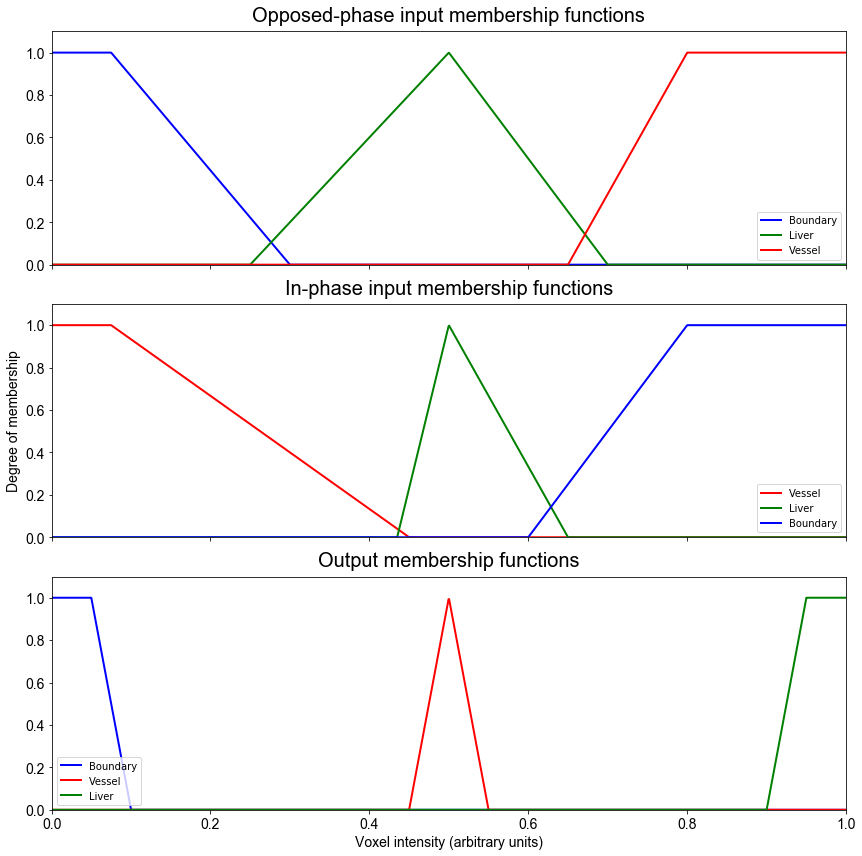

In [38]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager

# Generate universe variables
#   * Quality and service on subjective ranges [0, 10]
#   * Tip has a range of [0, 25] in units of percentage points
x_OP = np.linspace(0, 1, 1500)
x_IP = np.linspace(0, 1, 1500)
x_out  = np.linspace(0, 1, 1500)

# Generate fuzzy membership functions
OP_boundary = fuzz.trapmf(x_OP, [0, 0, 0.15*0.5, 0.6*0.5])
OP_liver = fuzz.trimf(x_OP, [0.5*0.5, 0.5, 1.4*0.5])
OP_vessel = fuzz.trapmf(x_OP, [1.3*0.5, 1.6*0.5, 1, 1])

IP_vessel = fuzz.trapmf(x_IP, [0, 0, 0.15*0.5, 0.9*0.5])
IP_liver = fuzz.trimf(x_IP, [0.87*0.5, 0.5, 1.3*0.5])
IP_boundary = fuzz.trapmf(x_IP, [1.2*0.5, 1.6*0.5, 1, 1])

out_boundary = fuzz.trapmf(x_out, [0, 0, 0.05, 0.1])
out_vessel = fuzz.trimf(x_out, [0.45, 0.5, 0.55])
out_liver = fuzz.trapmf(x_out, [0.9, 0.95, 1, 1])

title_font = {'fontname':'Arial', 'size':'20', 'color':'black', 'weight':'normal',
              'verticalalignment':'bottom'} # Bottom vertical alignment for more space
axis_font = {'fontname':'Arial', 'size':'14'}

font_path = 'C:\Windows\Fonts\Arial.ttf'
font_prop = font_manager.FontProperties(fname=font_path, size=14)

# Visualize these universes and membership functions
fig, (ax0, ax1, ax2) = plt.subplots(nrows=3, figsize=(12, 12), sharex=True, sharey=True)

for label in (ax0.get_xticklabels() + ax0.get_yticklabels()):
    label.set_fontname('Arial')
    label.set_fontsize(14)
for label in (ax1.get_xticklabels() + ax1.get_yticklabels()):
    label.set_fontname('Arial')
    label.set_fontsize(14)
for label in (ax2.get_xticklabels() + ax2.get_yticklabels()):
    label.set_fontname('Arial')
    label.set_fontsize(14)

ax0.plot(x_OP, OP_boundary, 'b', linewidth=2, label='Boundary')
ax0.plot(x_OP, OP_liver, 'g', linewidth=2, label='Liver')
ax0.plot(x_OP, OP_vessel, 'r', linewidth=2, label='Vessel')
ax0.set_title('Opposed-phase input membership functions', **title_font)
ax0.legend(loc='lower right')

ax1.plot(x_IP, IP_vessel, 'r', linewidth=2, label='Vessel')
ax1.plot(x_IP, IP_liver, 'g', linewidth=2, label='Liver')
ax1.plot(x_IP, IP_boundary, 'b', linewidth=2, label='Boundary')
ax1.set_title('In-phase input membership functions', **title_font)
ax1.set_ylabel('Degree of membership', **axis_font)
ax1.legend(loc='lower right')

ax2.plot(x_out, out_boundary, 'b', linewidth=2, label='Boundary')
ax2.plot(x_out, out_vessel, 'r', linewidth=2, label='Vessel')
ax2.plot(x_out, out_liver, 'g', linewidth=2, label='Liver')
ax2.set_title('Output membership functions', **title_font)
ax2.set_xlabel('Voxel intensity (arbitrary units)', **axis_font)
ax2.legend(loc='best')

plt.tight_layout()
plt.axis([0,1,0,1.1])
plt.savefig('membership_function', dpi=100)
plt.show()

In [ ]:
'''# Turn off top/right axes
for ax in (ax0, ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.get_xaxis().tick_bottom()
    ax.get_yaxis().tick_left()'''